# Q1: Which past crashes predict future KSI crashes?

DOT picks camera sites partly by where people were killed or seriously injured (KSI). Is past KSI the best guide to future KSI? (issue #19)

**Findings**
- **Crash volume beats past KSI.** The model's top 1,000 sites catch about 16% of next year's KSI crashes; ranking by past KSI catches about 11%.
- **Use the model to rank, not to forecast.** For the very top sites, predicted counts run about 2× too high.
- **DOT's 2024 red light camera report:** our reconstructed camera sites match DOT's borough counts. DOT's "−65% right-angle crashes" compares camera sites with themselves before installation, with no comparison group. Sites picked for high past KSI fall to about a third of that level the next year with no intervention, so part of that drop would likely have happened anyway. Comparison sites drawn from these risk scores would give a fair estimate.

**Setup:** a *site* is every crash location within 100 ft of a busy point (results are similar at 50 or 150 ft). *KSI* is a death or a severe-injury complaint, a proxy because public data has no official serious-injury field. Injury coding changed in 2019, so only prediction years 2022–2025 are used. The model is fit on earlier years and tested on 2024 and 2025.

**Method: negative binomial regression.** For site $i$ in year $t$, the number of KSI crashes $y_{it}$ is modeled as a count with mean $\mu_{it}$:

$$\log \mu_{it} = \beta_0 + \sum_j \beta_j \log(1 + x_{ij,t}) + \gamma_t, \qquad \operatorname{Var}(y_{it}) = \mu_{it} + \alpha\,\mu_{it}^2$$

- $x_{ij,t}$ are the site's crash counts over the previous 3 years by type: property damage only, non-severe injury, non-fatal KSI, fatal, pedestrian casualties and cyclist casualties. Each crash falls in exactly one severity type, so the coefficients don't overlap.
- $\gamma_t$ is a year effect for citywide shifts; a future year uses the latest year's effect.
- The $\alpha\mu^2$ term is what makes this *negative binomial* rather than Poisson. It lets counts vary more than chance alone would explain, because sites differ in ways the history doesn't capture.
- Because of the $\log(1+x)$ form, **doubling** a past count multiplies expected KSI by about $2^{\beta_j}$; this is the "per doubling" effect in section 2.
- The model is fit by maximum likelihood, with standard errors clustered by site because each site appears in several years.

In [1]:
import logging
import sys
from pathlib import Path

sys.path.append("..")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import plotly.graph_objects as go
import plotly.io as pio

from model.count_models import HistoryRanker, NegativeBinomialModel
from preprocessing.panel import load_panel
from validation.validate import ValidationConfig, evaluate, poisson_interval, top_k_totals

logging.getLogger().setLevel(logging.WARNING)  # INFO shows rows dropped at each step
pio.renderers.default = "plotly_mimetype+notebook_connected"  # map also works in exported HTML

MODEL, PRACTICE, BOTH = "#2a78d6", "#eb6834", "#2b2b29"  # model, past-KSI practice, both lists
INK, INK_2, SURFACE = "#0b0b0b", "#52514e", "#fcfcfb"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "axes.edgecolor": INK_2,
    "axes.labelcolor": INK_2, "text.color": INK, "xtick.color": INK_2, "ytick.color": INK_2,
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
    "grid.color": "#e6e5e0", "grid.linewidth": 0.6, "axes.titlesize": 11,
    "axes.titleweight": "bold", "axes.titlelocation": "left", "font.size": 9.5,
})
pd.set_option("display.precision", 3)

In [2]:
panel, scoring, sites = load_panel()
print(f"{len(sites):,} sites, {len(panel):,} site-years ({panel.year.min()}-{panel.year.max()})")

89,073 sites, 356,292 site-years (2022-2025)


## 1. Model vs. ranking by past KSI
Share of next year's KSI crashes at the top-k sites; higher is better. The *no-camera* rows leave out every site that ever had a camera.

In [3]:
FEATURES = [f"log1p_{c}_lag3" for c in
            ["pdo", "injury_nonsevere", "ksi_nonfatal", "fatal", "ped_injured", "cyc_injured"]]
config = ValidationConfig()
methods = {
    "Past KSI": lambda: HistoryRanker("ksi_lag3", n_years=3),
    "Model": lambda: NegativeBinomialModel(FEATURES),
}
captures, calibrations, predictions = [], {}, {}
for name, make in methods.items():
    for subset, data in [("all sites", panel), ("no-camera sites", panel[~panel.camera_site])]:
        capture, calibration, preds = evaluate(make, data, config)
        captures.append(capture.assign(method=name, sites=subset))
        if subset == "all sites":
            calibrations[name], predictions[name] = calibration, preds

summary = (
    pd.concat(captures).query("k in [100, 500, 1000]")
    .pivot_table(index=["sites", "method"], columns="k", values="capture")
    .rename(columns=lambda k: f"top {k:,.0f}")
)
summary.style.format("{:.1%}")

## 2. What predicts KSI?
**Left:** sites ranked by one kind of past crash at a time. **Right:** the model's effect of each past count **per doubling**, holding the others fixed. 1 means no effect; bars are 95% intervals.

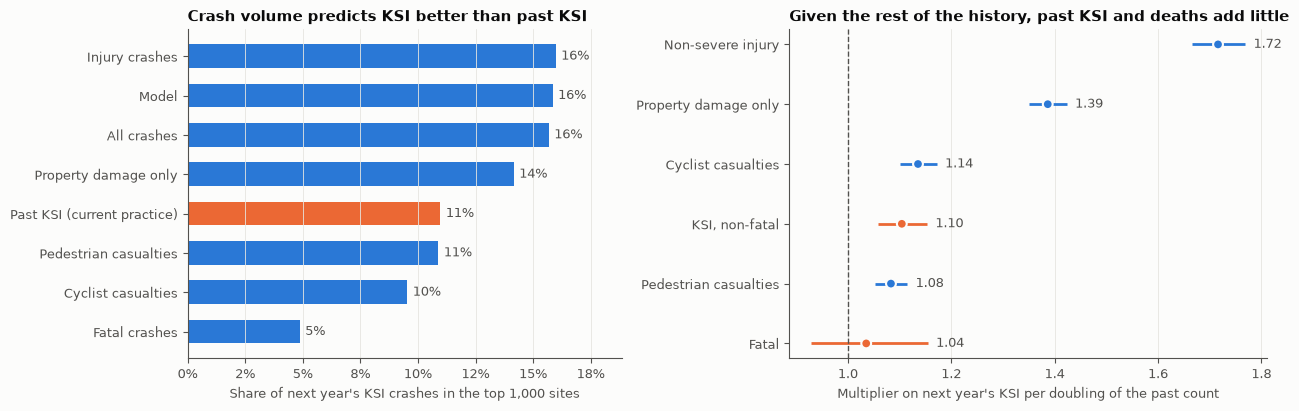

In [4]:
TOP_K = 1000
indicators = {
    "All crashes": "crashes_lag3", "Injury crashes": "injury_lag3",
    "Property damage only": "pdo_lag3", "Pedestrian casualties": "ped_injured_lag3",
    "Cyclist casualties": "cyc_injured_lag3", "Past KSI (current practice)": "ksi_lag3",
    "Fatal crashes": "fatal_lag3",
}
single = {}
for label, col in indicators.items():
    capture, _, _ = evaluate(lambda col=col: HistoryRanker(col), panel, config)
    single[label] = capture.query("k == @TOP_K")["capture"].mean()
single["Model"] = summary.loc[("all sites", "Model"), f"top {TOP_K:,}"]
single = pd.Series(single).sort_values()

final = NegativeBinomialModel(FEATURES).fit(panel, panel["ksi"], groups=panel["site_id"])
names = dict(zip(FEATURES, ["Property damage only", "Non-severe injury", "KSI, non-fatal", "Fatal",
                            "Pedestrian casualties", "Cyclist casualties"]))
# rate ratios are per unit of log(1 + count); ratio ** log(2) is the effect of doubling the count
effects = (
    final.coefficients().loc[FEATURES, ["ratio", "ci_low", "ci_high"]]
    .pow(np.log(2)).set_axis(["ratio", "low", "high"], axis=1)
    .rename(index=names).sort_values("ratio")
)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.2), gridspec_kw={"width_ratios": [1, 1.1]})
bars = ax1.barh(single.index, single.values, height=0.6,
                color=[PRACTICE if "Past KSI" in k else MODEL for k in single.index])
ax1.bar_label(bars, labels=[f"{v:.0%}" for v in single.values], padding=4, color=INK_2)
ax1.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax1.set_xlim(0, single.max() * 1.18)
ax1.grid(axis="y", visible=False)
ax1.set_xlabel(f"Share of next year's KSI crashes in the top {TOP_K:,} sites")
ax1.set_title("Crash volume predicts KSI better than past KSI")

y = np.arange(len(effects))
color = np.where(effects.index.str.contains("KSI|Fatal"), PRACTICE, MODEL)
ax2.hlines(y, effects.low, effects.high, color=color, linewidth=2)
ax2.scatter(effects.ratio, y, color=color, s=50, zorder=3, edgecolor=SURFACE, linewidth=1.5)
for yi, r in zip(y, effects.itertuples()):
    ax2.annotate(f"{r.ratio:.2f}", (r.high, yi), xytext=(6, 0), textcoords="offset points",
                 va="center", color=INK_2)
ax2.axvline(1, color=INK_2, linestyle="--", linewidth=1)
ax2.set_yticks(y, effects.index)
ax2.grid(axis="y", visible=False)
ax2.set_xlabel("Multiplier on next year's KSI per doubling of the past count")
ax2.set_title("Given the rest of the history, past KSI and deaths add little")
fig.tight_layout()

## 3. How accurate are the predicted counts?
**Predicted ÷ actual** KSI crashes in 2024–2025: 1× means the prediction was right, 2× means twice as many were predicted as happened. **Left:** sites grouped by predicted risk, with narrower groups toward the top. **Right:** watch lists of each method's top k sites.

The top of any ranking includes sites that had an unlucky few years, and that luck doesn't repeat (*regression to the mean*). So predictions for top sites run high, and past KSI taken at face value runs about 3× too high.

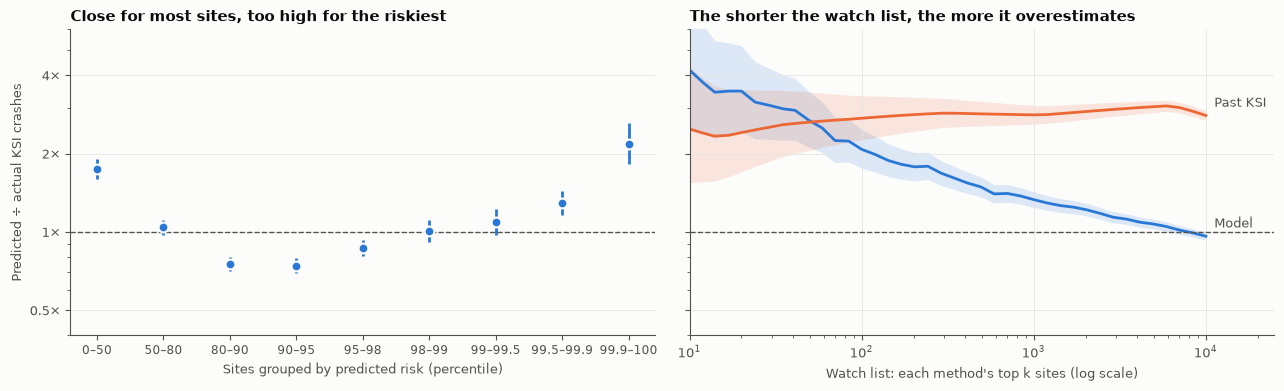

Model top 100, 2024 + 2025: 284 KSI crashes predicted, 137 happened (2.1x)


In [5]:
cal = (
    calibrations["Model"]
    .groupby(["bin", "q_low", "q_high"])[["pred_total", "obs_total"]].sum().reset_index()
)
low, high = poisson_interval(cal["obs_total"])
# predicted / actual, with the 95% interval of the actual count flipped into the ratio
cal = cal.assign(ratio=cal.pred_total / cal.obs_total, low=cal.pred_total / high, high=cal.pred_total / low)

ks = np.unique(np.round(np.logspace(1, 4, 40)).astype(int))
rows = []
for name, preds in predictions.items():
    by_year = list(preds.groupby("year"))
    for k in ks:
        p, o = np.sum([top_k_totals(d["ksi"], d["pred"], k) for _, d in by_year], axis=0)
        rows.append({"method": name, "k": k, "pred": p, "obs": o})
tail = pd.DataFrame(rows)
low, high = poisson_interval(tail["obs"])
tail = tail.assign(ratio=tail.pred / tail.obs, low=tail.pred / high, high=tail.pred / low)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.0), sharey=True)
x = np.arange(len(cal))
ax1.vlines(x, cal["low"], cal["high"], color=MODEL, linewidth=2)
ax1.scatter(x, cal["ratio"], color=MODEL, s=50, zorder=3, edgecolor=SURFACE, linewidth=1.5)
ax1.set_xticks(x, [f"{lo * 100:g}–{hi * 100:g}" for lo, hi in zip(cal.q_low, cal.q_high)], fontsize=8.5)
ax1.set_xlabel("Sites grouped by predicted risk (percentile)")
ax1.set_ylabel("Predicted ÷ actual KSI crashes")
ax1.grid(axis="x", visible=False)
ax1.set_title("Close for most sites, too high for the riskiest")
for name, color in [("Model", MODEL), ("Past KSI", PRACTICE)]:
    d = tail[tail.method == name]
    ax2.fill_between(d.k, d.low, d.high, color=color, alpha=0.15, linewidth=0)
    ax2.plot(d.k, d.ratio, color=color, linewidth=2)
    ax2.annotate(name, (d.k.iloc[-1], d.ratio.iloc[-1]), xytext=(6, 4),
                 textcoords="offset points", va="bottom", color=INK_2)
ax2.set_xscale("log")
ax2.set_xlim(ks.min(), ks.max() * 2.5)
ax2.set_xlabel("Watch list: each method's top k sites (log scale)")
ax2.set_title("The shorter the watch list, the more it overestimates")
for ax in (ax1, ax2):
    ax.axhline(1, color=INK_2, linestyle="--", linewidth=1)
ax1.set_yscale("log")  # so 2x too high and 2x too low are the same distance from 1x
ax1.set_yticks([0.5, 1, 2, 4], ["0.5×", "1×", "2×", "4×"])
ax1.yaxis.set_minor_formatter(plt.NullFormatter())
ax1.set_ylim(0.4, 6)
fig.tight_layout()
plt.show()

r = tail.query("method == 'Model' and k == 100").iloc[0]
print(f"Model top 100, 2024 + 2025: {r.pred:,.0f} KSI crashes predicted, {r.obs:,.0f} happened ({r.ratio:.1f}x)")

## 4. Comparison with DOT's 2024 Red Light Camera Program Review
**Left:** red light camera intersections by borough in 2023, from DOT's report and from our reconstruction from ticket data.

**Right:** DOT measured camera effects as *before vs. after at the same sites*, with no comparison group (−65% right-angle injury crashes). The chart applies that method to the 100 sites with the most KSI crashes in the prior 3 years, *without any camera being installed*: their KSI rate still falls sharply the next year. Part of DOT's reported drop would likely have happened anyway. Comparing camera sites with similar-risk sites from this model would separate the camera effect.

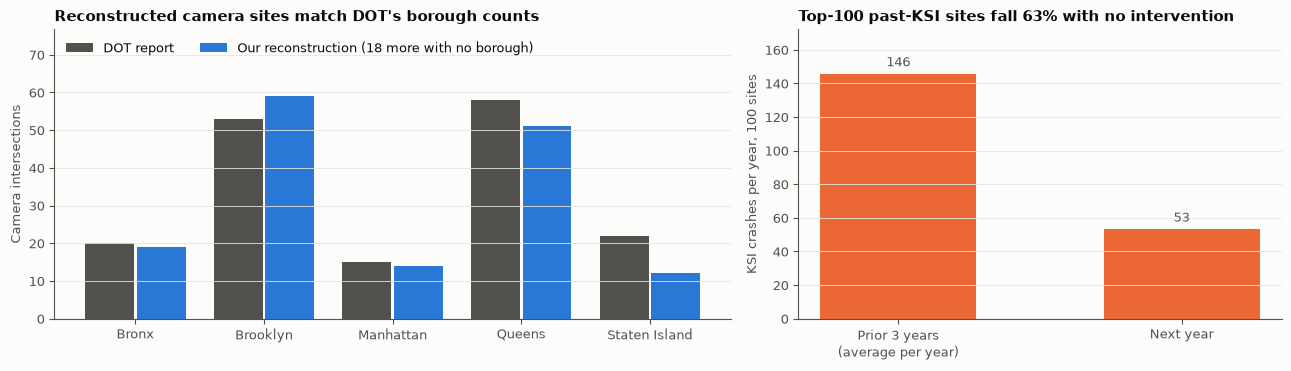

In [6]:
# DOT, NYC Red Light Camera Program Review 2024 Report, p. 12 (sums to more than 150 because cameras rotate)
dot = pd.Series({"BRONX": 20, "BROOKLYN": 53, "MANHATTAN": 15, "QUEENS": 58, "STATEN ISLAND": 22})
rlc_sites = panel.query("year == 2023 and rlc_active").site_id
ours = sites.set_index("site_id").loc[rlc_sites, "borough"].value_counts().reindex(dot.index)
unknown = len(rlc_sites) - ours.sum()

past = tail.query("method == 'Past KSI' and k == 100").iloc[0]
n_years = len(config.test_years)
before_after = pd.Series({"Prior 3 years\n(average per year)": past.pred / n_years,
                          "Next year": past.obs / n_years})

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 3.8), gridspec_kw={"width_ratios": [1.4, 1]})
x = np.arange(len(dot))
ax1.bar(x - 0.2, dot.values, width=0.38, color=INK_2, label="DOT report")
ax1.bar(x + 0.2, ours.values, width=0.38, color=MODEL, label=f"Our reconstruction ({unknown} more with no borough)")
ax1.set_xticks(x, [b.title() for b in dot.index])
ax1.grid(axis="x", visible=False)
ax1.set_ylabel("Camera intersections")
ax1.set_ylim(0, max(dot.max(), ours.max()) * 1.3)
ax1.legend(frameon=False, loc="upper left", ncol=2)
ax1.set_title("Reconstructed camera sites match DOT's borough counts")

bars = ax2.bar(before_after.index, before_after.values, color=PRACTICE, width=0.55)
ax2.bar_label(bars, labels=[f"{v:.0f}" for v in before_after.values], padding=3, color=INK_2)
ax2.grid(axis="x", visible=False)
ax2.set_ylabel("KSI crashes per year, 100 sites")
ax2.set_ylim(0, before_after.max() * 1.18)
ax2.set_title(f"Top-100 past-KSI sites fall {1 - past.obs / past.pred:.0%} with no intervention")
fig.tight_layout()

## 5. Risk score for every site
Expected KSI crashes in the year after the data ends. The full table is saved to `experiments/outputs/` (git-ignored).

In [7]:
risk = (
    scoring.assign(expected_ksi=final.predict(scoring))
    .merge(sites[["site_id", "borough", "latitude", "longitude"]], on="site_id")
    .sort_values("expected_ksi", ascending=False)
    .assign(rank=lambda d: np.arange(1, len(d) + 1))
)
year = risk["year"].iloc[0]
Path("outputs").mkdir(exist_ok=True)
risk.to_parquet(Path("outputs") / f"q1_site_risk_{year}.parquet")
risk[["rank", "expected_ksi", "ksi_lag3", "crashes_lag3", "camera_site", "borough"]].head(10).set_index("rank")

,expected_ksi,ksi_lag3,crashes_lag3,camera_site,borough
rank,,,,,
1,3.993,6.0,172.0,False,BRONX
2,3.299,2.0,143.0,True,BROOKLYN
3,2.639,4.0,114.0,False,BRONX
4,2.511,1.0,121.0,True,BROOKLYN
5,2.409,1.0,195.0,False,NaN
6,2.336,2.0,109.0,True,BROOKLYN
7,2.330,2.0,119.0,False,BRONX
8,2.308,3.0,121.0,True,BRONX
9,2.280,3.0,131.0,False,QUEENS


## 6. Map
Hover for details; click a legend entry to show or hide it. The past-KSI list is partly arbitrary because many sites tie at its cutoff.

In [8]:
model_top = risk.head(100)
past_top = risk.sort_values(["ksi_lag3", "site_id"], ascending=[False, True]).head(100)
both = set(model_top.site_id) & set(past_top.site_id)
layers = {
    "Model top 100": (model_top[~model_top.site_id.isin(both)], MODEL),
    "Past-KSI top 100": (past_top[~past_top.site_id.isin(both)], PRACTICE),
    f"On both lists ({len(both)})": (model_top[model_top.site_id.isin(both)], BOTH),
}
hover = ("<b>%{customdata[0]}</b><br>Model rank: %{customdata[1]:,}<br>Expected KSI: %{customdata[2]:.2f}<br>"
         "Past 3 yrs: %{customdata[3]:.0f} KSI, %{customdata[4]:.0f} crashes<br>Camera site: %{customdata[5]}"
         "<extra></extra>")
fig = go.Figure()
for label, (d, color) in layers.items():
    fig.add_trace(go.Scattermap(
        lat=d.latitude, lon=d.longitude, mode="markers", name=label,
        marker={"size": 6 + 6 * np.sqrt(d.expected_ksi), "color": color, "opacity": 0.85},
        customdata=np.column_stack([np.full(len(d), label), d["rank"], d.expected_ksi, d.ksi_lag3,
                                    d.crashes_lag3, np.where(d.camera_site, "yes", "no")]).astype(object),
        hovertemplate=hover,
    ))
fig.update_layout(
    map={"style": "carto-positron", "center": {"lat": 40.71, "lon": -73.93}, "zoom": 9.6},
    height=700, margin={"l": 0, "r": 0, "t": 40, "b": 0}, title=f"Highest-risk sites for {year}",
    legend={"x": 0.01, "y": 0.99, "bgcolor": "rgba(252,252,251,0.85)"},
)
fig.show()